# Stage 4 — Exploratory Data Analysis and Feature Engineering

This notebook runs **after** `02_data_cleaning_final.ipynb`. It explores the cleaned player data, summarizes differences among spending segments, creates a small set of interpretable gameplay features, and exports a modeling dataset.

**Business purpose:** identify player behaviors that may help NovaPlay Studios tailor future campaigns. The analysis describes associations; it does not establish that a behavior causes spending.


## Prediction-time and leakage guardrail

This notebook assumes the model will use information available at the end of the 30-day observation window to predict a **later** spending outcome. Confirm that timing when defining the target. If `SpendingSegment` was calculated from spending during the same 30 days, this is retrospective classification rather than a valid forecast; a future outcome window is required for a real deployment claim.

To reduce direct target leakage, the model-ready output excludes `InAppPurchaseAmount`, `PurchaseCount30d`, `FirstPurchaseDaysAfterInstall`, `PaymentMethod`, and purchase/date outcome fields. `SessionCount`, `AverageSessionLength`, and `WinRate` are also withheld from the modeling output until their observation windows are confirmed. `UserID` is excluded because it is an identifier. Review demographic fields for fairness and privacy before deployment.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, kruskal

PROJECT_DIR = Path.cwd()
INPUT_FILE = PROJECT_DIR / "02_clean_data.csv"
OUTPUT_DIR = PROJECT_DIR / "03_eda_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
TARGET = "SpendingSegment"

sns.set_theme(style="whitegrid", context="notebook")


In [2]:
if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Could not find {INPUT_FILE.name}. Run the cleaning notebook first and place this notebook beside the cleaned CSV."
    )

df = pd.read_csv(INPUT_FILE)
required_columns = {
    TARGET, "Age", "Device", "GameGenre", "AcquisitionChannel",
    "ActiveDays30d", "PlayerLevel30d", "AdsWatched30d",
    "SocialActions30d", "WinRate", "GuildMember",
    "PushNotificationsOptIn",
}
missing_columns = sorted(required_columns.difference(df.columns))
if missing_columns:
    raise ValueError(f"Required cleaned columns are missing: {missing_columns}")

assert df[TARGET].notna().all(), "The target contains missing values."
print(f"Dataset size: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Missing cells: {int(df.isna().sum().sum()):,}")
print(f"Exact duplicate rows: {int(df.duplicated().sum()):,}")
display(df.head())


Dataset size: 247,500 rows × 23 columns
Missing cells: 0


Exact duplicate rows: 0


,UserID,Age,Gender,Country,Device,GameGenre,SessionCount,AverageSessionLength,SpendingSegment,InAppPurchaseAmount,...,AcquisitionChannel,InstallDate,ActiveDays30d,PlayerLevel30d,AdsWatched30d,SocialActions30d,GuildMember,PushNotificationsOptIn,PurchaseCount30d,WinRate
0,c9889ab0-9cfc-4a75-acd9-5eab1df0015c,49.0,Male,Norway,Android,Battle Royale,9.0,12.83,Minnow,11.40,...,Organic,2024-01-30,6.0,12.0,5.0,4.0,No,Yes,1.0,0.4
1,7c9e413c-ecca-45f2-a780-2826a07952a2,15.0,Male,Switzerland,iOS,Action RPG,11.0,19.39,Minnow,6.37,...,Organic,2024-01-30,6.0,12.0,5.0,4.0,No,Yes,1.0,0.4
2,fd61e419-1a92-4f43-a8c7-135842ad328a,23.0,Male,China,Android,Fighting,9.0,8.87,Minnow,15.81,...,Organic,2024-01-30,6.0,12.0,5.0,4.0,No,Yes,1.0,0.4
3,bdb7f6d1-ff9a-468c-afe7-43f32a94293e,31.0,Male,Mexico,Android,Racing,12.0,19.56,Minnow,13.49,...,Organic,2024-01-30,6.0,12.0,5.0,4.0,No,Yes,1.0,0.4
4,aa7eec14-4846-47b9-b879-9c98038cda04,37.0,Female,India,Android,Battle Royale,10.0,15.23,Minnow,10.86,...,Organic,2024-01-30,6.0,12.0,5.0,4.0,No,Yes,1.0,0.4


## 1. Target distribution

Check how many players belong to each segment before modeling. The large class imbalance means accuracy alone can hide poor Whale detection; later model evaluation should include per-class recall, precision, macro-F1, and a confusion matrix.


,Players,Percent
SpendingSegment,,
Minnow,208328,84.17
Dolphin,33670,13.60
Whale,5502,2.22


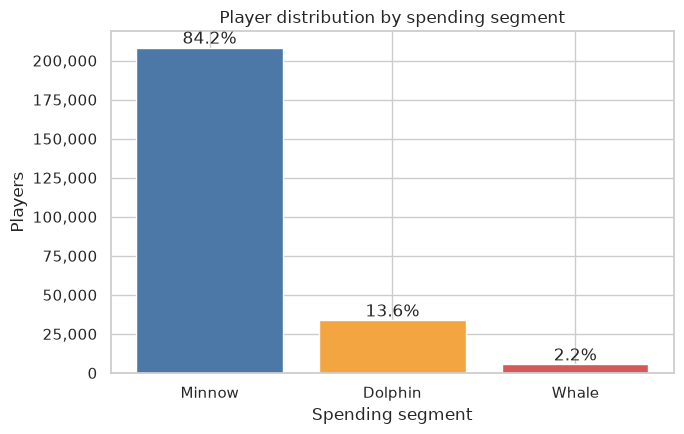

In [3]:
segment_counts = df[TARGET].value_counts().reindex(["Minnow", "Dolphin", "Whale"]).dropna()
segment_share = (segment_counts / len(df) * 100).rename("Percent")
target_summary = pd.concat([segment_counts.rename("Players"), segment_share], axis=1)
display(target_summary.round(2))

fig, ax = plt.subplots(figsize=(7, 4.5))
colors = ["#4C78A8", "#F2A541", "#D45A5A"][:len(segment_counts)]
bars = ax.bar(segment_counts.index, segment_counts.values, color=colors)
ax.set_title("Player distribution by spending segment")
ax.set_ylabel("Players")
ax.set_xlabel("Spending segment")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
for bar, pct in zip(bars, segment_share):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{pct:.1f}%", ha="center", va="bottom")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "target_distribution.png", dpi=180, bbox_inches="tight")
plt.show()


## 2. Numeric behavior profiles by segment

Use medians and interquartile ranges because player-behavior measures can be skewed. Kruskal–Wallis tests check whether at least one segment differs; epsilon-squared is included as an effect-size estimate. With a large dataset, a small p-value is not automatically a meaningful business difference, so review the group medians and effect size too.


In [4]:
NUMERIC_FEATURES = [
    "Age", "SessionCount", "AverageSessionLength", "ActiveDays30d",
    "PlayerLevel30d", "AdsWatched30d", "SocialActions30d", "WinRate",
]
NUMERIC_FEATURES = [c for c in NUMERIC_FEATURES if c in df.columns]

long = df[[TARGET] + NUMERIC_FEATURES].melt(
    id_vars=TARGET, var_name="Feature", value_name="Value"
)
segment_order = [x for x in ["Minnow", "Dolphin", "Whale"] if x in df[TARGET].unique()]

numeric_summary = (
    df.groupby(TARGET)[NUMERIC_FEATURES]
      .agg(["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
)
numeric_summary.columns = [f"{feature}_{stat}" for feature, stat in numeric_summary.columns]
display(numeric_summary.round(3))

results = []
for feature in NUMERIC_FEATURES:
    groups = [pd.to_numeric(df.loc[df[TARGET] == label, feature], errors="coerce").dropna() for label in segment_order]
    groups = [g for g in groups if len(g)]
    if len(groups) >= 2:
        h_stat, p_value = kruskal(*groups)
        n = sum(len(g) for g in groups)
        k = len(groups)
        epsilon_sq = max(0.0, (h_stat - k + 1) / (n - k)) if n > k else np.nan
        results.append({"Feature": feature, "Kruskal_H": h_stat, "p_value": p_value, "epsilon_squared": epsilon_sq})

kruskal_results = pd.DataFrame(results).sort_values("epsilon_squared", ascending=False)
def format_p_value(value):
    if value == 0:
        return "<1e-300 (numerical underflow)"
    return f"{value:.2e}" if value < 0.001 else f"{value:.4f}"

display(kruskal_results.assign(p_value=kruskal_results["p_value"].map(format_p_value)).round({"Kruskal_H":3,"epsilon_squared":6}))
kruskal_results.to_csv(OUTPUT_DIR / "numeric_segment_tests.csv", index=False)


,Age_median,Age_<lambda_0>,Age_<lambda_1>,SessionCount_median,SessionCount_<lambda_0>,SessionCount_<lambda_1>,AverageSessionLength_median,AverageSessionLength_<lambda_0>,AverageSessionLength_<lambda_1>,ActiveDays30d_median,...,PlayerLevel30d_<lambda_1>,AdsWatched30d_median,AdsWatched30d_<lambda_0>,AdsWatched30d_<lambda_1>,SocialActions30d_median,SocialActions30d_<lambda_0>,SocialActions30d_<lambda_1>,WinRate_median,WinRate_<lambda_0>,WinRate_<lambda_1>
SpendingSegment,,,,,,,,,,,,,,,,,,,,,
Dolphin,33.0,24.0,43.0,10.0,7.0,13.0,19.940,12.700,26.98,6.0,...,17.0,5.0,3.0,7.0,4.0,3.0,5.0,0.4,0.296,0.510
Minnow,33.0,24.0,43.0,10.0,7.0,13.0,19.940,12.850,27.13,6.0,...,17.0,5.0,4.0,7.0,4.0,3.0,5.0,0.4,0.296,0.510
Whale,35.0,25.0,45.0,11.0,8.0,14.0,16.575,10.902,23.13,7.0,...,18.0,5.0,4.0,7.0,4.0,3.0,6.0,0.4,0.297,0.515


,Feature,Kruskal_H,p_value,epsilon_squared
2,AverageSessionLength,435.181,3.17e-95,0.001750
1,SessionCount,211.338,1.28e-46,0.000846
3,ActiveDays30d,133.667,9.43e-30,0.000532
4,PlayerLevel30d,121.256,4.67e-27,0.000482
0,Age,67.944,1.76e-15,0.000266
5,AdsWatched30d,21.467,2.18e-05,0.000079
6,SocialActions30d,5.568,0.0618,0.000014
7,WinRate,0.754,0.6858,0.000000


/tmp/ipykernel_12233/3013977570.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y=feature, order=segment_order, showfliers=False, ax=ax, palette="Set2")


/tmp/ipykernel_12233/3013977570.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y=feature, order=segment_order, showfliers=False, ax=ax, palette="Set2")


/tmp/ipykernel_12233/3013977570.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y=feature, order=segment_order, showfliers=False, ax=ax, palette="Set2")


/tmp/ipykernel_12233/3013977570.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y=feature, order=segment_order, showfliers=False, ax=ax, palette="Set2")


/tmp/ipykernel_12233/3013977570.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y=feature, order=segment_order, showfliers=False, ax=ax, palette="Set2")


/tmp/ipykernel_12233/3013977570.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y=feature, order=segment_order, showfliers=False, ax=ax, palette="Set2")


/tmp/ipykernel_12233/3013977570.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y=feature, order=segment_order, showfliers=False, ax=ax, palette="Set2")


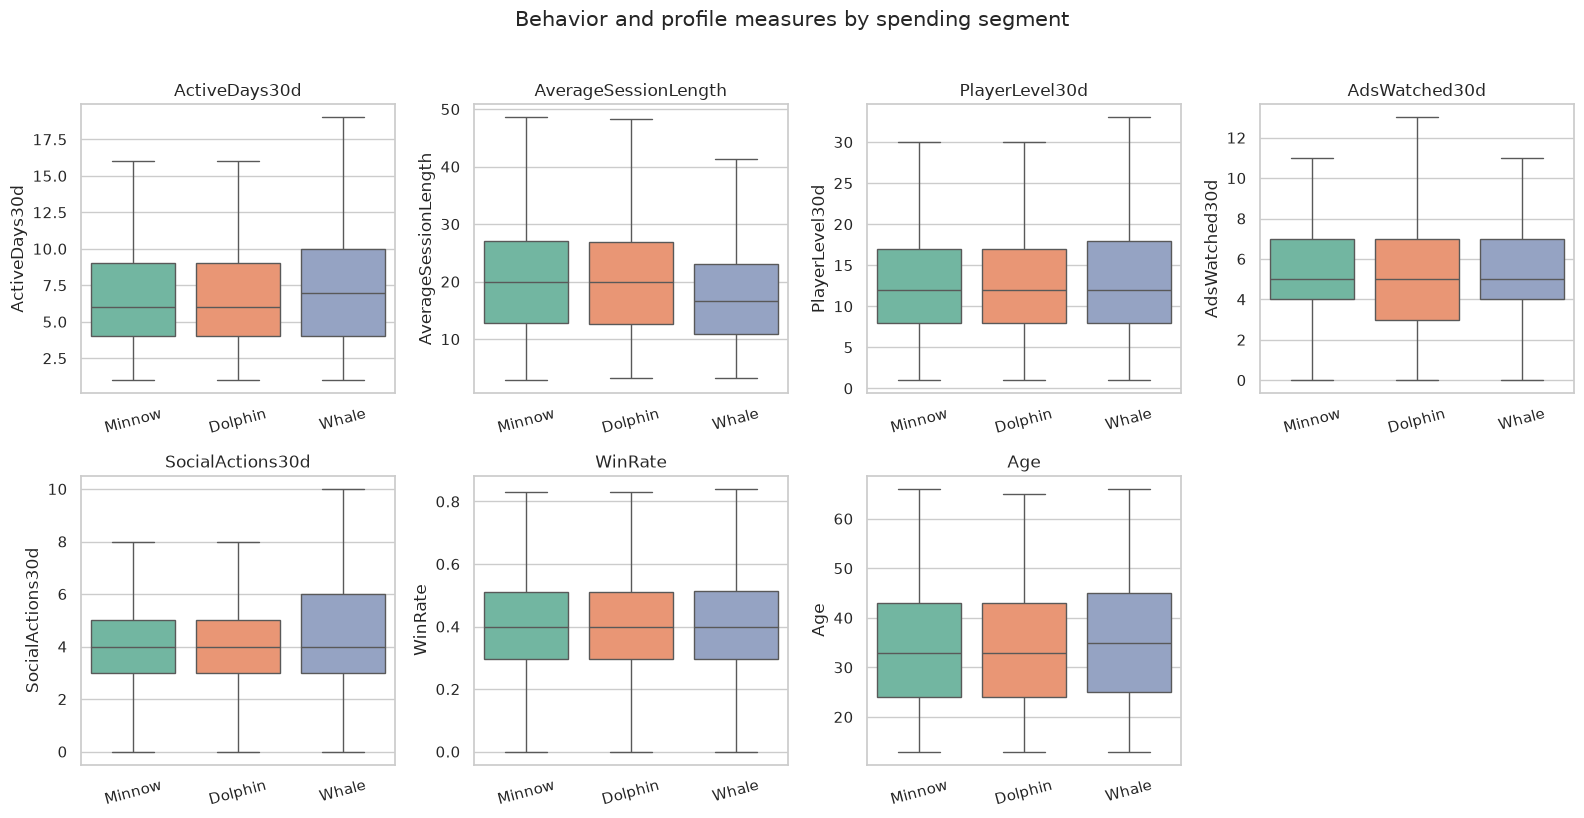

Boxplot fliers are hidden for readability only; those records are not removed from the dataset.


In [5]:
plot_features = [
    c for c in ["ActiveDays30d", "AverageSessionLength", "PlayerLevel30d",
                "AdsWatched30d", "SocialActions30d", "WinRate", "Age"]
    if c in df.columns
]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for ax, feature in zip(axes, plot_features):
    sns.boxplot(data=df, x=TARGET, y=feature, order=segment_order, showfliers=False, ax=ax, palette="Set2")
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
for ax in axes[len(plot_features):]:
    ax.remove()
fig.suptitle("Behavior and profile measures by spending segment", y=1.02, fontsize=15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "numeric_by_segment.png", dpi=180, bbox_inches="tight")
plt.show()
print("Boxplot fliers are hidden for readability only; those records are not removed from the dataset.")


## 3. Feature engineering

Create rates from measures that share the same 30-day observation window. Per-active-day rates help distinguish a player who is active on many days from one who performs the same number of actions on fewer days. The original input columns remain available for audit. A days-active fraction would be a constant rescaling of `ActiveDays30d`, so it is not added as a separate predictor. `SessionCount` is not converted to a per-day rate because its time window is not explicitly stated in the column name.


In [6]:
fe = df.copy()

# Convert the activity counters to numeric values before feature creation.
rate_inputs = ["ActiveDays30d", "PlayerLevel30d", "AdsWatched30d", "SocialActions30d"]
for column in rate_inputs:
    fe[column] = pd.to_numeric(fe[column], errors="raise")

active_days = fe["ActiveDays30d"].clip(lower=0, upper=30)

def per_active_day(numerator, denominator):
    safe_denominator = denominator.where(denominator > 0, np.nan)
    return (numerator / safe_denominator).replace([np.inf, -np.inf], np.nan).fillna(0)

fe["PlayerLevelPerActiveDay30d"] = per_active_day(fe["PlayerLevel30d"].clip(lower=0), active_days)
fe["AdsPerActiveDay30d"] = per_active_day(fe["AdsWatched30d"].clip(lower=0), active_days)
fe["SocialActionsPerActiveDay30d"] = per_active_day(fe["SocialActions30d"].clip(lower=0), active_days)

ENGINEERED_FEATURES = [
    "PlayerLevelPerActiveDay30d", "AdsPerActiveDay30d",
    "SocialActionsPerActiveDay30d",
]
display(fe[ENGINEERED_FEATURES + [TARGET]].head())


,PlayerLevelPerActiveDay30d,AdsPerActiveDay30d,SocialActionsPerActiveDay30d,SpendingSegment
0,2.0,0.833333,0.666667,Minnow
1,2.0,0.833333,0.666667,Minnow
2,2.0,0.833333,0.666667,Minnow
3,2.0,0.833333,0.666667,Minnow
4,2.0,0.833333,0.666667,Minnow


,PlayerLevelPerActiveDay30d_median,PlayerLevelPerActiveDay30d_<lambda_0>,PlayerLevelPerActiveDay30d_<lambda_1>,AdsPerActiveDay30d_median,AdsPerActiveDay30d_<lambda_0>,AdsPerActiveDay30d_<lambda_1>,SocialActionsPerActiveDay30d_median,SocialActionsPerActiveDay30d_<lambda_0>,SocialActionsPerActiveDay30d_<lambda_1>
SpendingSegment,,,,,,,,,
Dolphin,2.0,1.333,2.857,0.800,0.500,1.333,0.636,0.364,1.0
Minnow,2.0,1.333,2.857,0.800,0.500,1.333,0.667,0.375,1.0
Whale,2.0,1.333,2.750,0.714,0.438,1.243,0.600,0.333,1.0


/tmp/ipykernel_12233/3787271552.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=fe, x=TARGET, y=feature, order=segment_order, showfliers=False, ax=ax, palette="Set2")


/tmp/ipykernel_12233/3787271552.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=fe, x=TARGET, y=feature, order=segment_order, showfliers=False, ax=ax, palette="Set2")


/tmp/ipykernel_12233/3787271552.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=fe, x=TARGET, y=feature, order=segment_order, showfliers=False, ax=ax, palette="Set2")


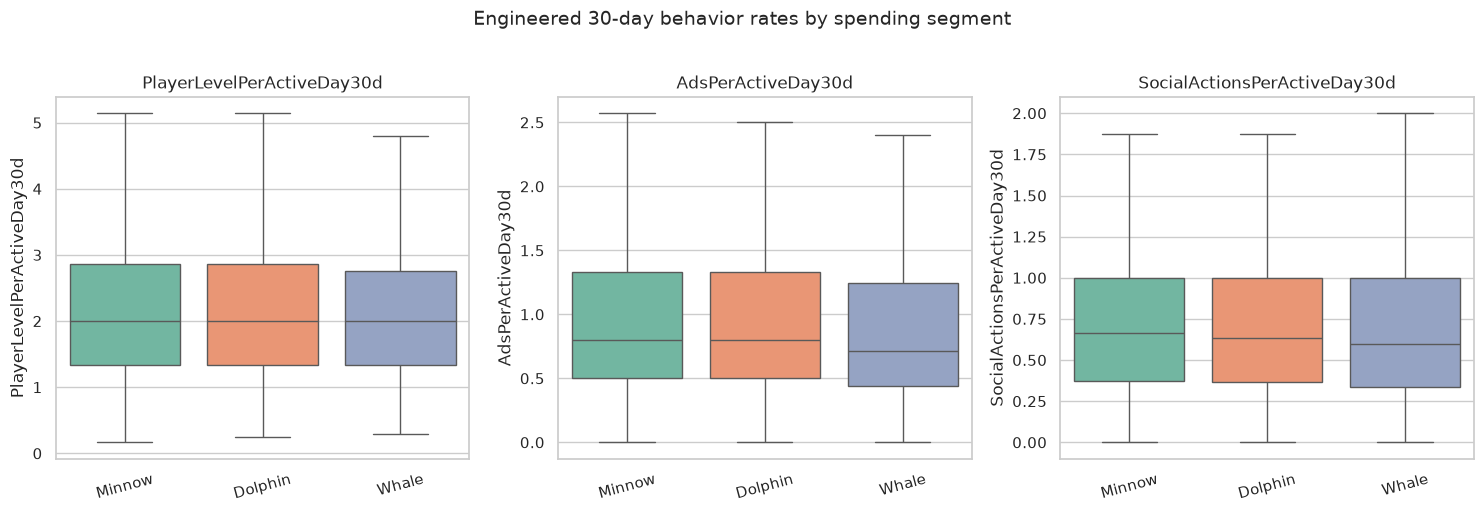

In [7]:
engineered_summary = (
    fe.groupby(TARGET)[ENGINEERED_FEATURES]
      .agg(["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
)
engineered_summary.columns = [f"{feature}_{stat}" for feature, stat in engineered_summary.columns]
display(engineered_summary.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, feature in zip(axes.flatten(), ENGINEERED_FEATURES):
    sns.boxplot(data=fe, x=TARGET, y=feature, order=segment_order, showfliers=False, ax=ax, palette="Set2")
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
fig.suptitle("Engineered 30-day behavior rates by spending segment", y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "engineered_features_by_segment.png", dpi=180, bbox_inches="tight")
plt.show()


## 4. Categorical patterns

Compare within-segment percentages rather than raw counts, so the much larger Minnow group does not dominate the charts. For high-cardinality fields, the chart shows the most common values; the full table remains available in the output. Cramér’s V gives an association-size summary for the chi-square test.


,Feature,Chi_square,p_value,Cramers_V
6,Country,4045.929,<1e-300 (numerical underflow),0.090408
1,GameGenre,2916.955,<1e-300 (numerical underflow),0.076765
5,Gender,406.516,1.09e-86,0.028657
0,Device,27.034,1.35e-06,0.010451
3,GuildMember,19.983,4.58e-05,0.008986
4,PushNotificationsOptIn,6.554,0.0377,0.005146
2,AcquisitionChannel,8.696,0.5612,0.004191


Business readout from this cleaned file:
- Audience mix: Minnow 84.17%, Dolphin 13.60%, Whale 2.22%.
- 30-day behavioral group differences (epsilon-squared):
         Feature  epsilon_squared
   ActiveDays30d         0.000532
  PlayerLevel30d         0.000482
   AdsWatched30d         0.000079
SocialActions30d         0.000014
- Practical reading: these effect sizes are small; the current 30-day behavior features do not sharply separate spending segments by themselves.
- GameGenre: Cramer's V=0.077, p-value <1e-300 (numerical underflow); association does not establish cause.
- AcquisitionChannel: Cramer's V=0.004, p-value 0.5612; association does not establish cause.
- Country: Cramer's V=0.090, p-value <1e-300 (numerical underflow); association does not establish cause.
- Business implication: use the patterns to form offer-test hypotheses, and measure incremental revenue, margin, and retention in a randomized holdout.


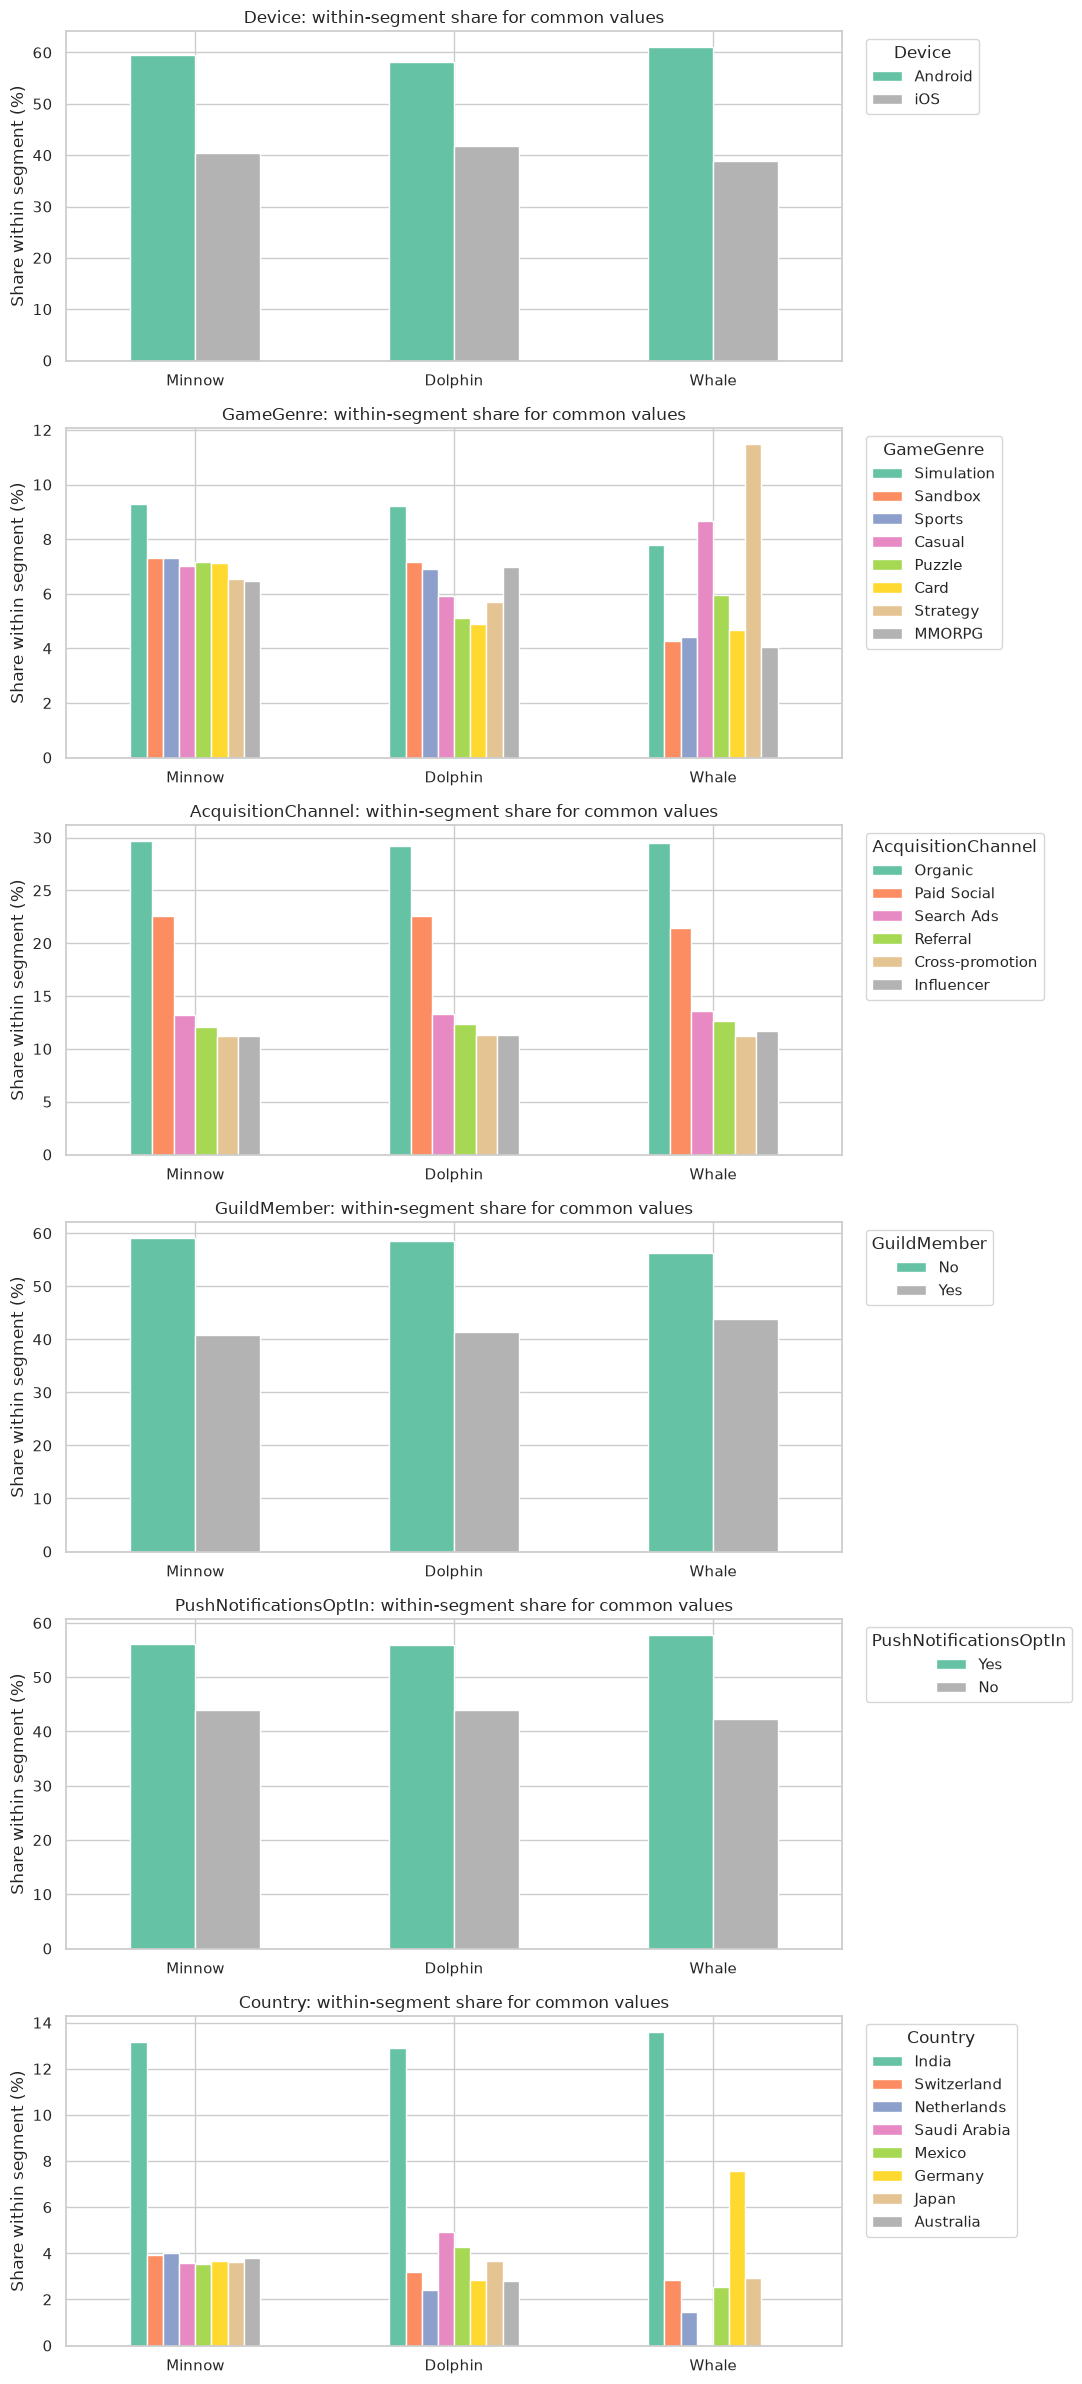

In [8]:
CATEGORICAL_FEATURES = [
    c for c in ["Device", "GameGenre", "AcquisitionChannel", "GuildMember", "PushNotificationsOptIn", "Gender", "Country"]
    if c in df.columns
]
cat_results = []
cat_tables = {}
for feature in CATEGORICAL_FEATURES:
    table = pd.crosstab(df[feature].fillna("Unknown"), df[TARGET])
    cat_tables[feature] = table
    if table.shape[0] > 1 and table.shape[1] > 1:
        chi2, p_value, _, _ = chi2_contingency(table)
        n = table.to_numpy().sum()
        denom = n * min(table.shape[0] - 1, table.shape[1] - 1)
        cramers_v = np.sqrt(chi2 / denom) if denom else np.nan
        cat_results.append({"Feature": feature, "Chi_square": chi2, "p_value": p_value, "Cramers_V": cramers_v})

cat_results = pd.DataFrame(cat_results).sort_values("Cramers_V", ascending=False)
display(cat_results.assign(p_value=cat_results["p_value"].map(format_p_value)).round({"Chi_square":3,"Cramers_V":6}))
cat_results.to_csv(OUTPUT_DIR / "categorical_segment_tests.csv", index=False)

print("Business readout from this cleaned file:")
print(f"- Audience mix: Minnow {segment_share.get('Minnow', 0):.2f}%, Dolphin {segment_share.get('Dolphin', 0):.2f}%, Whale {segment_share.get('Whale', 0):.2f}%.")
verified_30d = kruskal_results[kruskal_results["Feature"].isin(["ActiveDays30d", "PlayerLevel30d", "AdsWatched30d", "SocialActions30d"])].sort_values("epsilon_squared", ascending=False)
print("- 30-day behavioral group differences (epsilon-squared):")
print(verified_30d[["Feature", "epsilon_squared"]].round(6).to_string(index=False))
if not verified_30d.empty and verified_30d["epsilon_squared"].max() < 0.01:
    print("- Practical reading: these effect sizes are small; the current 30-day behavior features do not sharply separate spending segments by themselves.")
for feature in ["GameGenre", "AcquisitionChannel", "Country"]:
    row = cat_results[cat_results["Feature"] == feature]
    if not row.empty:
        print(f"- {feature}: Cramer's V={row.iloc[0]['Cramers_V']:.3f}, p-value {format_p_value(row.iloc[0]['p_value'])}; association does not establish cause.")
print("- Business implication: use the patterns to form offer-test hypotheses, and measure incremental revenue, margin, and retention in a randomized holdout.")

plot_cats = [c for c in ["Device", "GameGenre", "AcquisitionChannel", "GuildMember", "PushNotificationsOptIn", "Country"] if c in cat_tables]
fig, axes = plt.subplots(len(plot_cats), 1, figsize=(11, 4 * len(plot_cats)))
if len(plot_cats) == 1: axes = [axes]
for ax, feature in zip(axes, plot_cats):
    tab = cat_tables[feature]
    top_values = tab.sum(axis=1).sort_values(ascending=False).head(8).index
    pct = tab.loc[top_values].div(tab.sum(axis=0), axis=1).T * 100
    pct.reindex(segment_order).plot(kind="bar", stacked=False, ax=ax, colormap="Set2")
    ax.set_title(f"{feature}: within-segment share for common values")
    ax.set_ylabel("Share within segment (%)")
    ax.set_xlabel("")
    ax.legend(title=feature, bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "categorical_patterns.png", dpi=180, bbox_inches="tight")
plt.show()


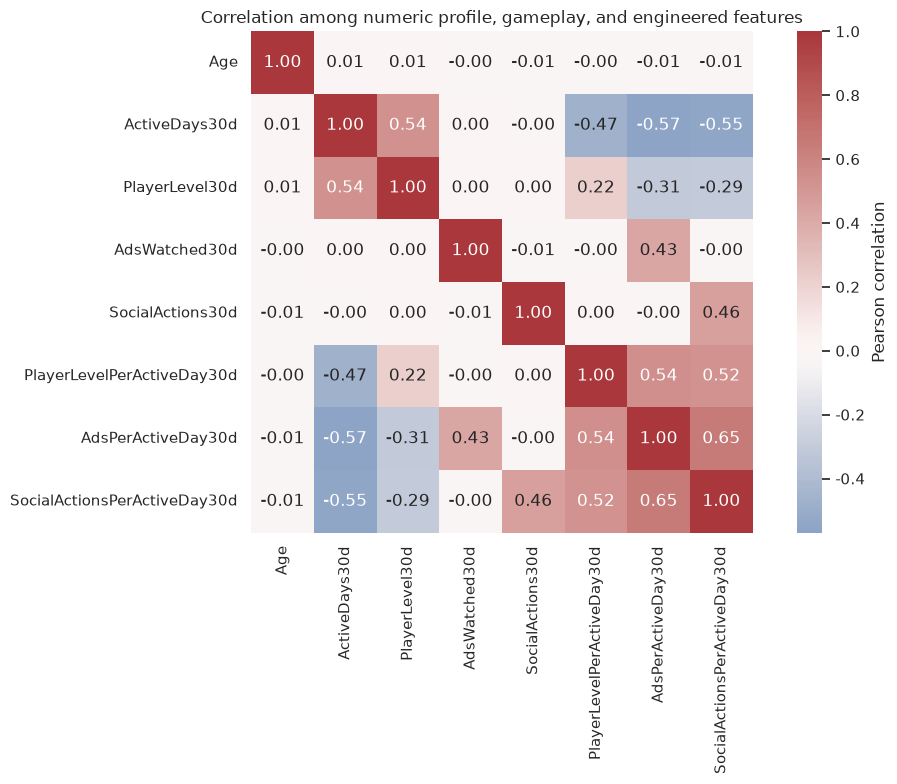

In [9]:
# Numeric correlation is descriptive only; high correlation does not prove causation.
correlation_features = [c for c in ["Age", "ActiveDays30d", "PlayerLevel30d", "AdsWatched30d", "SocialActions30d"] + ENGINEERED_FEATURES if c in fe.columns]
corr = fe[correlation_features].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", square=True, ax=ax, cbar_kws={"label":"Pearson correlation"})
ax.set_title("Correlation among numeric profile, gameplay, and engineered features")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "numeric_correlation.png", dpi=180, bbox_inches="tight")
plt.show()


## 5. Business interpretation

Use the printed tables and charts to write conclusions in practical terms:

- **Reach and evaluation:** segment shares show how large each campaign audience is. Because one segment is much larger, evaluate future models with Whale/Dolphin recall and macro-F1, not accuracy alone.
- **Offer design:** compare behavioral medians and within-segment category shares. If a segment is more active or opts into notifications more often, those traits can guide a controlled offer test; they do not prove that the trait causes purchases. Country and genre are high-cardinality associations, so inspect sample sizes and validate patterns before localizing offers.
- **Campaign operations:** the new rates describe behavior relative to active days, which may help separate broad activity from intensity on an active day. Test whether they improve validation performance before using them.
- **Measurement:** use a randomized holdout or A/B test to determine whether personalized offers increase incremental IAP revenue without lowering contribution margin or retention.
- **Leakage:** purchase fields must remain outside predictors unless they are measured before the prediction cutoff and are not part of how the label was defined.


In [10]:
# Build an analysis/modeling handoff file. Keep the target, but exclude identifiers and purchase-outcome fields.
TARGET = "SpendingSegment"
LEAKAGE_AND_ID_COLUMNS = [
    "UserID", "InAppPurchaseAmount", "PurchaseCount30d",
    "FirstPurchaseDaysAfterInstall", "PaymentMethod",
    "LastPurchaseDate", "InstallDate", "SessionCount",
    "AverageSessionLength", "WinRate",
]
excluded = [c for c in LEAKAGE_AND_ID_COLUMNS if c in fe.columns]
model_data = fe.drop(columns=excluded).copy()

# Keep the label explicit and unchanged.
y_original = df[TARGET].reset_index(drop=True)
y_exported = model_data[TARGET].reset_index(drop=True)
assert y_original.equals(y_exported), "Target values changed during feature engineering."
assert not set(LEAKAGE_AND_ID_COLUMNS).intersection(model_data.columns.drop(TARGET, errors="ignore"))

feature_columns = [c for c in model_data.columns if c != TARGET]
model_output = OUTPUT_DIR.parent / "03_feature_engineered.csv"
model_data.to_csv(model_output, index=False)
numeric_summary.to_csv(OUTPUT_DIR / "numeric_summary_by_segment.csv")
engineered_summary.to_csv(OUTPUT_DIR / "engineered_summary_by_segment.csv")

print(f"Saved modeling handoff: {model_output.name}")
print(f"Rows: {len(model_data):,}; candidate predictors: {len(feature_columns)}")
print("Excluded from predictors:", excluded)
print("Candidate predictors:", feature_columns)
print("\nTarget share (%):")
print((model_data[TARGET].value_counts(normalize=True).reindex(segment_order) * 100).round(2).to_string())
print("\nLargest numeric associations by epsilon-squared (descriptive, not causal):")
print(kruskal_results.head(5)[["Feature", "epsilon_squared", "p_value"]].round(6).to_string(index=False))
print(f"\nCharts and summary tables saved under: {OUTPUT_DIR}")


Saved modeling handoff: 03_feature_engineered.csv
Rows: 247,500; candidate predictors: 15
Excluded from predictors: ['UserID', 'InAppPurchaseAmount', 'PurchaseCount30d', 'FirstPurchaseDaysAfterInstall', 'PaymentMethod', 'LastPurchaseDate', 'InstallDate', 'SessionCount', 'AverageSessionLength', 'WinRate']
Candidate predictors: ['Age', 'Gender', 'Country', 'Device', 'GameGenre', 'AcquisitionChannel', 'ActiveDays30d', 'PlayerLevel30d', 'AdsWatched30d', 'SocialActions30d', 'GuildMember', 'PushNotificationsOptIn', 'PlayerLevelPerActiveDay30d', 'AdsPerActiveDay30d', 'SocialActionsPerActiveDay30d']

Target share (%):
SpendingSegment
Minnow     84.17
Dolphin    13.60
Whale       2.22

Largest numeric associations by epsilon-squared (descriptive, not causal):
             Feature  epsilon_squared  p_value
AverageSessionLength         0.001750      0.0
        SessionCount         0.000846      0.0
       ActiveDays30d         0.000532      0.0
      PlayerLevel30d         0.000482      0.0
    

## Modeling handoff

The exported `03_feature_engineered.csv` contains eligible candidate features and the unchanged target label. Before fitting a model, split into train/test sets first, then fit one-hot encoding, scaling, imputation (if needed), feature selection, and class balancing only on the training data using a pipeline. Keep the holdout set untouched for final evaluation. Review demographic variables for fairness and privacy, and re-add any withheld field only after verifying it is available at prediction time and measured within the intended observation window.
